# Week 5. Flows and guidance

This notebook accompanies Chapters 7 and 8 of the notes.

1. The probability flow ODE has the same marginals as the reverse SDE, but very different trajectories.
2. Flow matching learns an ODE directly, and rectified flow straightens its trajectories.
3. Guidance with a scale $\gamma\ne1$ does not sample from the sharpened target $q\,p(c\mid\cdot)^\gamma$, as an exactly solvable
   example shows.
4. Classifier-free guidance on MNIST.

Sections 1–3 run on a laptop CPU in about two minutes. Section 4 trains a conditional version of the Week 4
network, which takes about seven minutes on a recent laptop GPU. On a CPU you may want to reduce `NUM_STEPS`.

In [1]:
import math, contextlib, io
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision import datasets, transforms

from mnist_unet import UNet

rng = np.random.default_rng(5)
torch.manual_seed(5)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

device: mps


## 1. The probability flow ODE

The reverse SDE $\mathrm dY_t=[Y_t+2s_{T-t}(Y_t)]\,\mathrm dt+\sqrt2\,\mathrm dB_t$ and the probability flow ODE $\dot Y_t=Y_t+s_{T-t}(Y_t)$, both started
from $q_T$, have the same law $q_{T-t}$ at every time $t$. Their trajectories are completely different. The most striking
case is $q=\gamma_n$. Then $q_\tau=\gamma_n$ for all $\tau$, the score is $-x$, the ODE is $\dot Y_t=0$, and every point stays where it is, while the
reverse SDE is an OU process that forgets its starting point.

We also compare the two on the mixture of Week 3, $0.8\,\mathcal N(-ae_1,s^2I_n)+0.2\,\mathcal N(ae_1,s^2I_n)$ with $a=2.5$, $s=0.35$ and $n=20$, using
the exact scores.

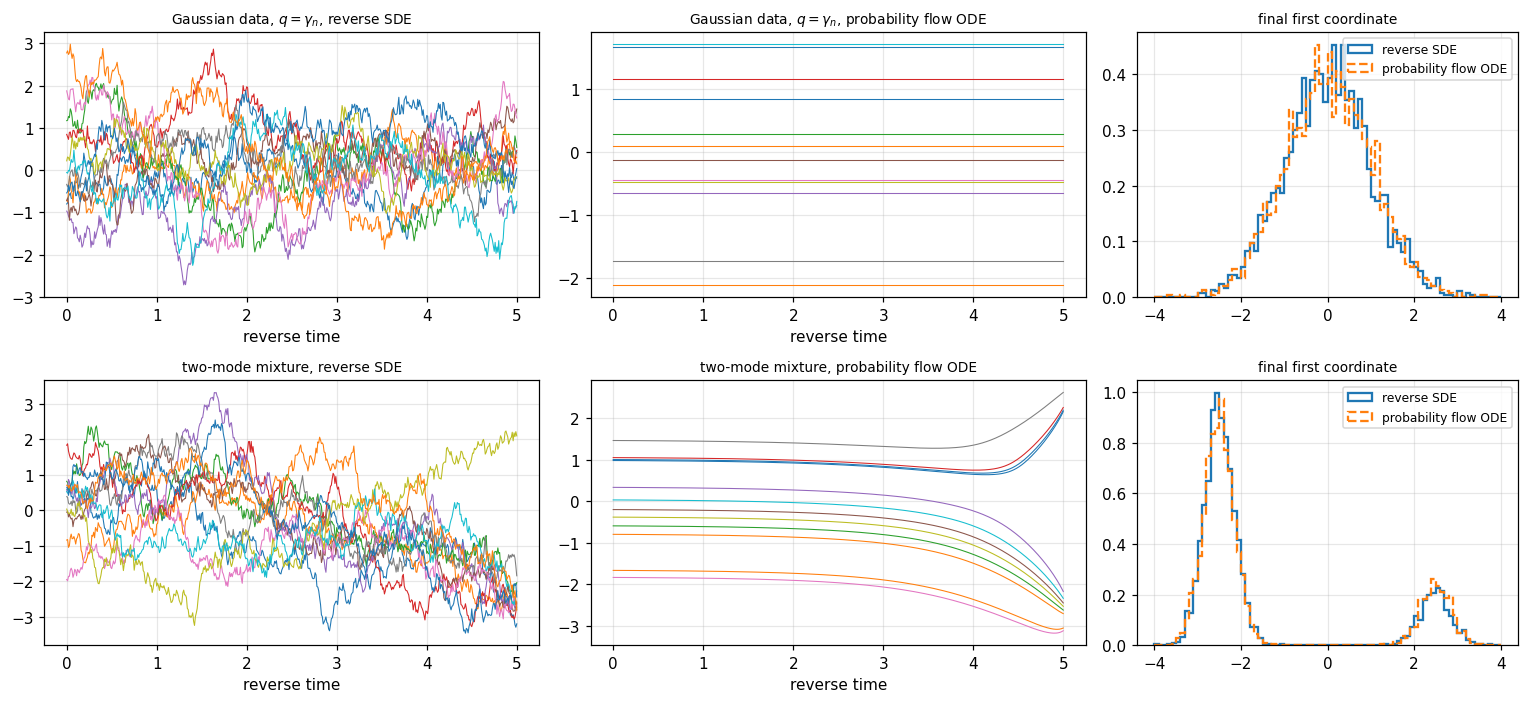

In [2]:
N_DIM, W_LEFT, S, A = 20, 0.8, 0.35, 2.5

def mixture_score(x, a, s2, shrink=1.0):
    m = np.zeros(x.shape[1]); m[0] = shrink * a
    dl, dr = x + m, x - m
    log_l = np.log(W_LEFT) - 0.5 * (dl**2).sum(1) / s2
    log_r = np.log(1 - W_LEFT) - 0.5 * (dr**2).sum(1) / s2
    r_l = 1 / (1 + np.exp(np.clip(log_r - log_l, -50, 50)))
    return -(r_l[:, None] * dl + (1 - r_l)[:, None] * dr) / s2

def noised_score(x, tau):
    return mixture_score(x, A, np.exp(-2 * tau) * S**2 + 1 - np.exp(-2 * tau), shrink=np.exp(-tau))

def run(score, stochastic, T=5.0, h=1e-3, M=3000, n=N_DIM, n_traj=12):
    y = rng.standard_normal((M, n)); traj = [y[:n_traj, 0].copy()]
    for k in range(int(T / h)):
        tau = T - k * h
        if stochastic:
            y = y + h * (y + 2 * score(y, tau)) + np.sqrt(2 * h) * rng.standard_normal(y.shape)
        else:
            y = y + h * (y + score(y, tau))
        if k % 10 == 0: traj.append(y[:n_traj, 0].copy())
    return y[:, 0], np.linspace(0, T, len(traj)), np.array(traj)

fig, ax = plt.subplots(2, 3, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.3, 1.3, 1]})
for row, (score, name) in enumerate([(lambda y, tau: -y, r"Gaussian data, $q=\gamma_n$"), (noised_score, "two-mode mixture")]):
    finals = {}
    for col, (stoch, label) in enumerate([(True, "reverse SDE"), (False, "probability flow ODE")]):
        final, ts, traj = run(score, stoch)
        finals[label] = final
        ax[row, col].plot(ts, traj, lw=0.7); ax[row, col].set_title(f"{name}, {label}", fontsize=9)
        ax[row, col].set_xlabel("reverse time")
    for label, ls in [("reverse SDE", "-"), ("probability flow ODE", "--")]:
        ax[row, 2].hist(finals[label], bins=80, range=(-4, 4), density=True, histtype="step", ls=ls, lw=1.5, label=label)
    ax[row, 2].set_title("final first coordinate", fontsize=9); ax[row, 2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In both rows the two final histograms agree, but the ODE trajectories are smooth and deterministic once the
initial point is drawn, while the SDE trajectories keep fluctuating. For Gaussian data the ODE does nothing at all.
Because they only match marginals, ODE samplers cannot be analysed with the path-space relative entropy of
Chapter 6, which is infinite between the two path laws.

## 2. Flow matching and rectified flow

Flow matching learns an ODE without any score. Given noise $X_0\sim\gamma_n$ and data $X_1\sim q$, independent, the straight
line $X_t=(1-t)X_0+tX_1$ has velocity $X_1-X_0$. The ODE with velocity $v_t(x)=\mathbb E[X_1-X_0\mid X_t=x]$ has the same marginals
as $X_t$, and $v$ is learned by least squares, minimising $\mathbb E|v_\theta(X_t,t)-(X_1-X_0)|^2$. We use data in the plane, a
mixture of eight Gaussians on a circle, only so that the trajectories can be drawn.

In [3]:
def sample_data(N):
    angles = 2 * np.pi * rng.integers(0, 8, N) / 8
    return np.stack([4 * np.cos(angles), 4 * np.sin(angles)], 1) + 0.3 * rng.standard_normal((N, 2))

class VelocityNet(nn.Module):
    def __init__(self, width=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, width), nn.SiLU(), nn.Linear(width, width), nn.SiLU(),
                                 nn.Linear(width, width), nn.SiLU(), nn.Linear(width, 2))
    def forward(self, x, t):
        return self.net(torch.cat([x, t[:, None]], 1))

def train_flow(pairs_fn, steps=5000, batch=512):
    v = VelocityNet(); opt = torch.optim.Adam(v.parameters(), lr=1e-3)
    for _ in range(steps):
        x0, x1 = pairs_fn(batch); t = torch.rand(batch)
        xt = (1 - t[:, None]) * x0 + t[:, None] * x1
        loss = ((v(xt, t) - (x1 - x0))**2).sum(1).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return v

@torch.no_grad()
def integrate(v, x0, K, keep=False):
    x = x0.clone(); path = [x.clone()]
    for k in range(K):
        x = x + v(x, torch.full((len(x),), k / K)) / K
        path.append(x.clone())
    return (x, torch.stack(path)) if keep else x

independent = lambda b: (torch.randn(b, 2), torch.tensor(sample_data(b), dtype=torch.float32))
flow1 = train_flow(independent)

Rectified flow then *reflows*. It integrates the learned ODE accurately to pair each noise point $Z_0$ with its
image $Z_1$, and trains a second flow on the straight lines between these pairs. Chapter 7 shows that the new
coupling has smaller transport cost, and that the lines of a coupling that does not cross are followed exactly by
the flow. Then a single Euler step suffices.

transport cost E|X1 - X0|^2: independent coupling 18.21, rectified coupling 7.88


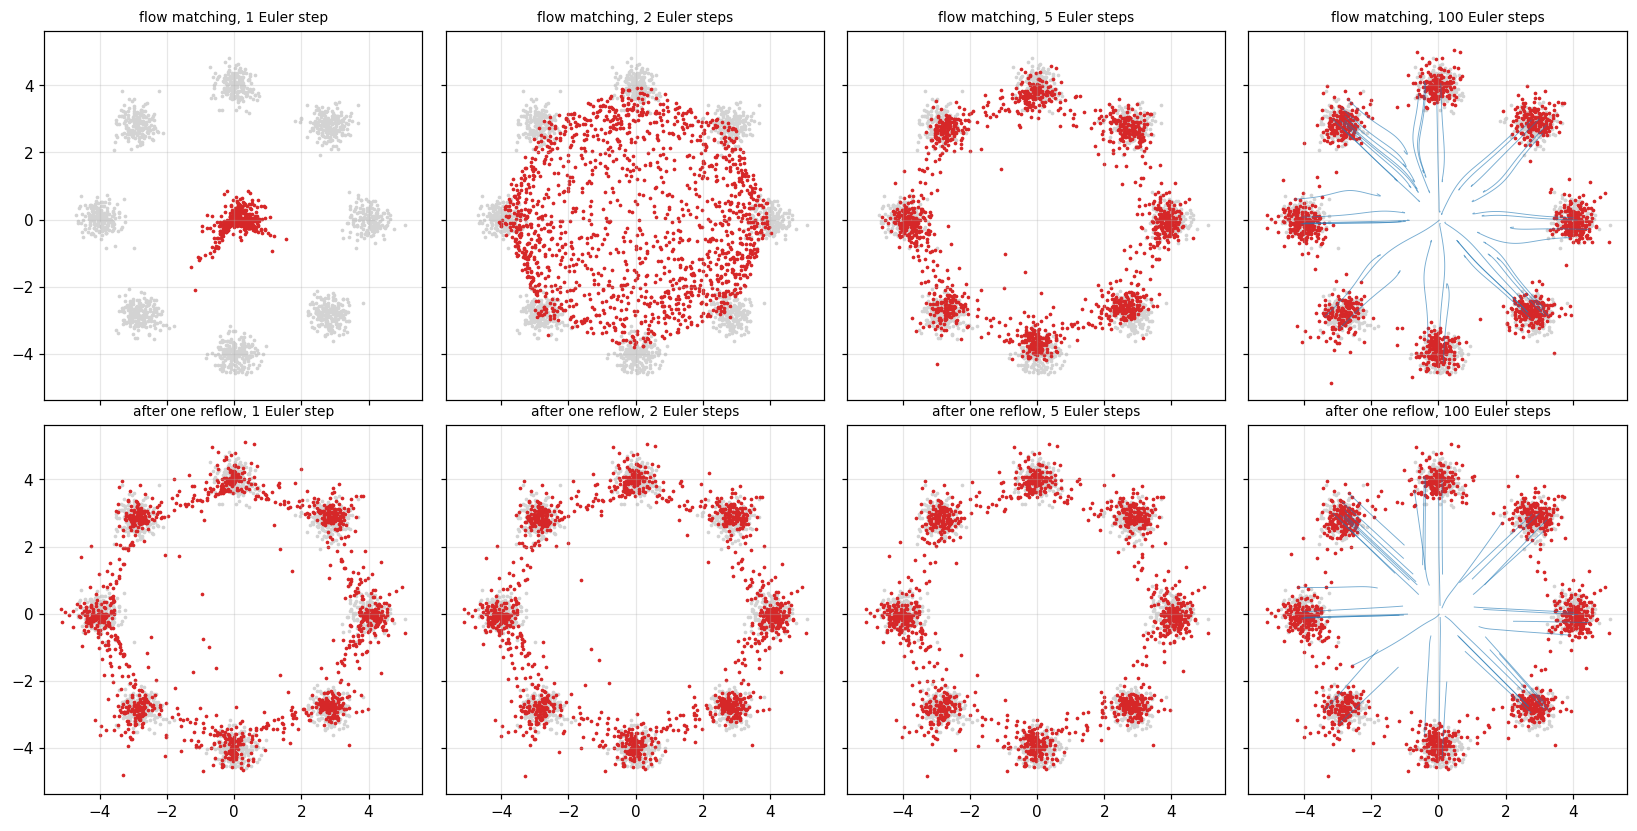

In [4]:
z0 = torch.randn(20_000, 2)
z1 = integrate(flow1, z0, 200)
print(f"transport cost E|X1 - X0|^2: independent coupling {np.mean(((sample_data(20_000) - rng.standard_normal((20_000, 2)))**2).sum(1)):.2f}, "
      f"rectified coupling {((z1 - z0)**2).sum(1).mean():.2f}")
reflowed = lambda b: (lambda i: (z0[i], z1[i]))(torch.randint(0, len(z0), (b,)))
flow2 = train_flow(reflowed)

x0 = torch.randn(1500, 2); target = sample_data(1500)
fig, ax = plt.subplots(2, 4, figsize=(15, 7.5), sharex=True, sharey=True)
for row, (v, name) in enumerate([(flow1, "flow matching"), (flow2, "after one reflow")]):
    for col, K in enumerate([1, 2, 5, 100]):
        out, path = integrate(v, x0, K, keep=True)
        a_ = ax[row, col]
        a_.scatter(*target.T, s=2, c="lightgray")
        if K == 100:
            for i in range(40):
                a_.plot(path[:, i, 0], path[:, i, 1], lw=0.6, c="tab:blue", alpha=0.6)
        a_.scatter(*out.numpy().T, s=2, c="tab:red")
        a_.set_title(f"{name}, {K} Euler step{'s' if K > 1 else ''}", fontsize=9); a_.set_aspect("equal")
plt.tight_layout(); plt.show()

The first flow needs many steps, because its trajectories bend to avoid each other. After one reflow the
trajectories are almost straight, and one or two Euler steps already produce good samples.

## 3. Guidance with a scale $\gamma\ne1$

In Chapter 8, guidance multiplies the classifier term of the conditional score by a scale $\gamma$. For $\gamma=1$ this is exact
conditioning, a Doob transform. For $\gamma\ne1$ it is tempting to think that the guided sampler targets the sharpened law
$\pi^\gamma\propto q\,p(c\mid\cdot)^\gamma$, but it does not. A model where everything is explicit shows the difference. The data are
$\bar X_0\sim\gamma_n$, and the label is a noisy measurement $C=\bar X_0+\eta\xi$. Then
$$
  \pi^\gamma=\mathcal N\Bigl(\frac{\gamma c}{\gamma+\eta^2},\frac{\eta^2}{\gamma+\eta^2}I_n\Bigr),\qquad
  s^\gamma_\tau(x)=-x+\frac{\gamma e^{-\tau}(c-e^{-\tau}x)}{\sigma_\tau^2+\eta^2},
$$
and Chapter 8 computes the law of the output of the guided reverse SDE. As $T\to\infty$ it is Gaussian with mean $c(1-r^\gamma)$ and
variance $\eta^2(1-r^{2\gamma-1})/(2\gamma-1)$ in each coordinate, where $r=\eta^2/(1+\eta^2)$. We check this by simulation in dimension $n=50$.

In [5]:
n, eta, T, h = 50, 1.0, 8.0, 1e-3
c = 1.5 * np.ones(n)
r = eta**2 / (1 + eta**2)
print(f"{'gamma':>6} | {'simulated mean':>15} {'predicted':>9} {'pi^gamma':>9} | {'simulated var':>14} {'predicted':>9} {'pi^gamma':>9}")
for gamma in [1.0, 2.0, 4.0]:
    y = rng.standard_normal((4000, n))
    for k in range(int(T / h) - 1):
        tau = T - k * h; s2 = 1 - np.exp(-2 * tau)
        score = -y + gamma * np.exp(-tau) * (c - np.exp(-tau) * y) / (s2 + eta**2)
        y = y + h * (y + 2 * score) + np.sqrt(2 * h) * rng.standard_normal(y.shape)
    m_sim = y.mean() / 1.5; v_sim = y.var(0).mean()          # mean in units of c, variance per coordinate
    print(f"{gamma:6.1f} | {m_sim:15.3f} {1 - r**gamma:9.3f} {gamma / (gamma + eta**2):9.3f} | "
          f"{v_sim:14.3f} {eta**2 * (1 - r**(2 * gamma - 1)) / (2 * gamma - 1):9.3f} {eta**2 / (gamma + eta**2):9.3f}")

 gamma |  simulated mean predicted  pi^gamma |  simulated var predicted  pi^gamma


   1.0 |           0.501     0.500     0.500 |          0.503     0.500     0.500


   2.0 |           0.749     0.750     0.667 |          0.295     0.292     0.333


   4.0 |           0.938     0.938     0.800 |          0.143     0.142     0.200


The means are in units of $c$. For $\gamma=1$ the three columns agree, since guidance is exact conditioning. For $\gamma>1$ the guided
sampler overshoots the mean of the sharpened target and is more concentrated than it. The Feynman–Kac
correction of Section 8.4 explains why, and gives the importance weights that would turn the guided samples into
samples of $\pi^\gamma$.

## 4. Classifier-free guidance on MNIST

We train the network of Week 4 with an extra input, the digit label, which is replaced by a null label $\varnothing$ in 10% of
the training examples. The same network then estimates both the conditional noise $\hat Z(x,c)$ and the unconditional
one $\hat Z(x,\varnothing)$. Classifier-free guidance samples with
$$
  \tilde Z^\gamma=\hat Z(x,\varnothing)+\gamma\bigl[\hat Z(x,c)-\hat Z(x,\varnothing)\bigr],
$$
which corresponds to the score $\nabla\log q_\tau+\gamma\nabla\log p_\tau(c\mid\cdot)$.

In [6]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: 2 * x - 1)])
with contextlib.redirect_stderr(io.StringIO()):
    mnist = datasets.MNIST(root="data", train=True, download=True, transform=transform)
images = torch.stack([mnist[i][0] for i in range(len(mnist))]).to(device)
labels = mnist.targets.to(device)

T, TAU_MIN, NUM_STEPS, BATCH, P_DROP, NULL = 5.0, 1e-3, 6000, 128, 0.1, 10
sigma = lambda tau: torch.sqrt(1 - torch.exp(-2 * tau))

model = UNet(base=32, num_classes=10).to(device)
ckpt = Path("checkpoints/week5_conditional_unet.pt")
if ckpt.exists():
    model.load_state_dict(torch.load(ckpt, map_location=device)); print("loaded", ckpt)
else:
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=NUM_STEPS)
    for step in range(NUM_STEPS):
        idx = torch.randint(0, len(images), (BATCH,), device=device)
        x0, y = images[idx], labels[idx].clone()
        y[torch.rand(BATCH, device=device) < P_DROP] = NULL                    # drop the label
        tau = torch.exp(math.log(TAU_MIN) + (math.log(T) - math.log(TAU_MIN)) * torch.rand(BATCH, device=device))
        z = torch.randn_like(x0)
        xt = torch.exp(-tau)[:, None, None, None] * x0 + sigma(tau)[:, None, None, None] * z
        loss = ((model(xt, tau, y) - z)**2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    ckpt.parent.mkdir(exist_ok=True); torch.save(model.state_dict(), ckpt)
model.eval();

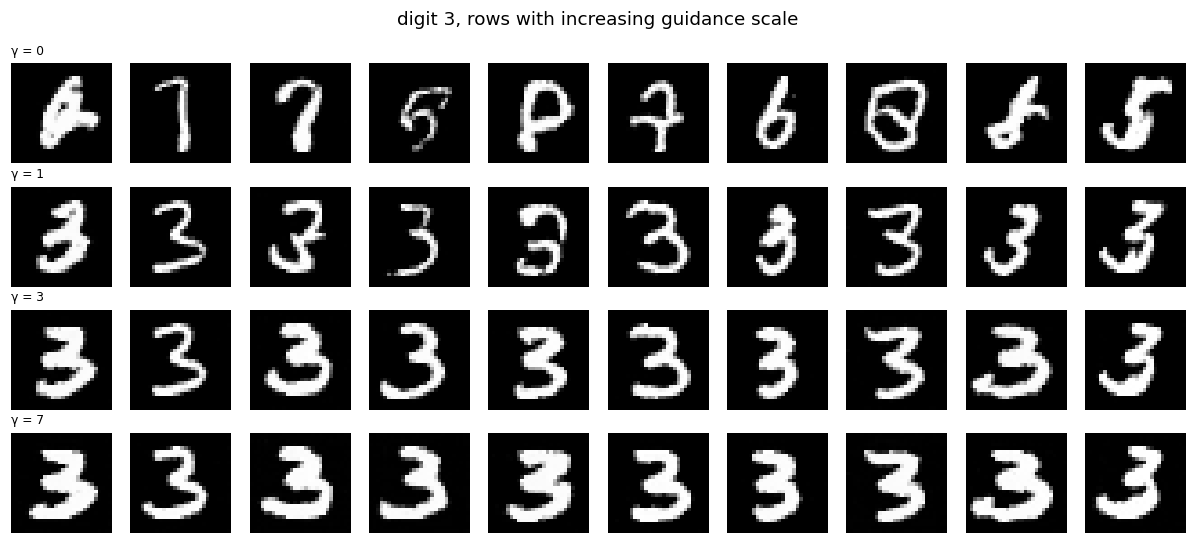

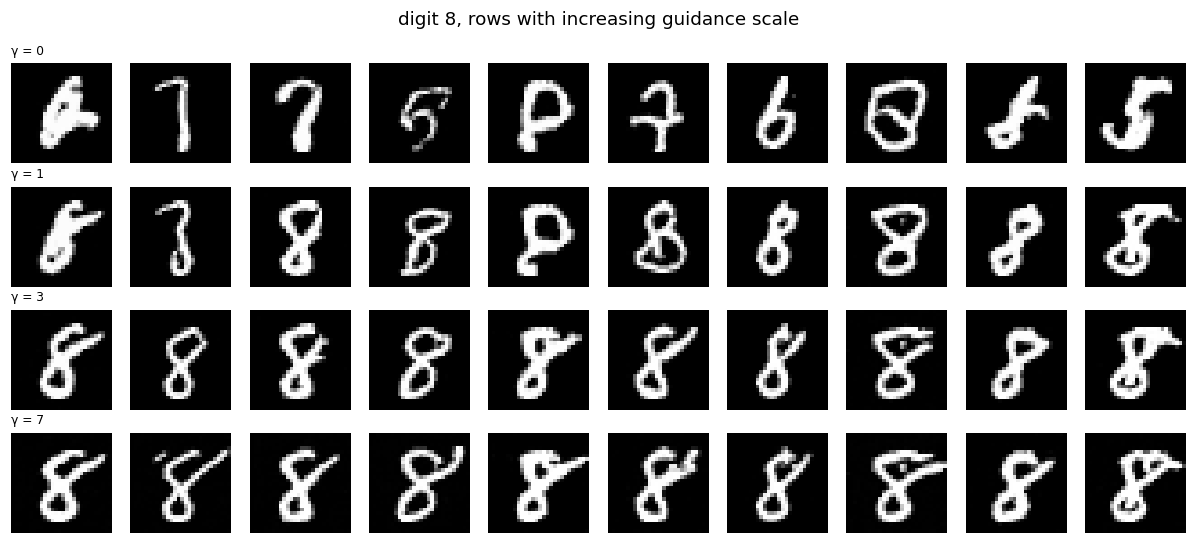

In [7]:
def grid(T, delta, K):
    return np.concatenate([np.linspace(0, T - 1, K // 2 + 1), (T - np.geomspace(1.0, delta, K - K // 2 + 1))[1:]])

@torch.no_grad()
def sample_cfg(digit, gamma, M=10, K=300, delta=1e-3):
    c = torch.full((M,), digit, device=device); null = torch.full((M,), NULL, device=device)
    def z_hat(y, tau):
        z_null = model(y, tau, null)
        return z_null if gamma == 0 else z_null + gamma * (model(y, tau, c) - z_null)
    ts = grid(T, delta, K); y = torch.randn(M, 1, 28, 28, device=device)
    for t0, t1 in zip(ts[:-1], ts[1:]):
        h = float(t1 - t0); tau = torch.full((M,), T - t0, device=device)
        score = -z_hat(y, tau) / sigma(tau)[:, None, None, None]
        y = math.exp(h) * y + 2 * (math.exp(h) - 1) * score + math.sqrt(math.exp(2 * h) - 1) * torch.randn_like(y)
    tau = torch.full((M,), delta, device=device)
    return math.exp(delta) * (y - sigma(tau)[:, None, None, None] * z_hat(y, tau))

gammas = [0.0, 1.0, 3.0, 7.0]
for digit in [3, 8]:
    fig, ax = plt.subplots(len(gammas), 10, figsize=(11, 1.25 * len(gammas)))
    for i, gamma in enumerate(gammas):
        torch.manual_seed(0)
        imgs = sample_cfg(digit, gamma).clamp(-1, 1).cpu()
        for j in range(10):
            ax[i, j].imshow(imgs[j, 0], cmap="gray", vmin=-1, vmax=1); ax[i, j].axis("off")
        ax[i, 0].set_title(f"γ = {gamma:g}", fontsize=8, loc="left")
    fig.suptitle(f"digit {digit}, rows with increasing guidance scale"); plt.tight_layout(); plt.show()

With $\gamma=0$ the samples are unconditional, with all digits mixed. With $\gamma=1$ the network samples from its estimate of the
conditional distribution, which is mostly, but not always, the requested digit. Larger scales make the digit
unmistakable and the strokes bolder, and the samples become more and more alike. This loss of diversity is the
sharpening of Section 3. In practice too large a scale eventually produces artefacts, since the guided score
leaves the range of what the network was trained on.

*Things to try.* Compare `gamma = 3` with the unguided conditional model by counting how often the requested
digit appears. Replace the stochastic sampler by the probability flow ODE, using the drift $y+s$ instead of $y+2s$ and no
noise, and see how few steps it needs.